In [1]:
import heapq

graph = {
    'A': [('B',1), ('C',4)],
    'B': [('D',2), ('E',5)],
    'C': [('E',1)],
    'D': [('G',5)],
    'E': [('G',2)],
    'G': []
}

heuristic = {
    'A':5,
    'B':4,
    'C':2,
    'D':5,
    'E':1,
    'G':0
}

start = 'A'
goal = 'G'
pq = []

heapq.heappush(pq, (0,0,start))

visited = []
parent = {start: None}
g_cost = {start: 0}

while pq:
    f, g, node = heapq.heappop(pq)
    print("Visited :", node)

    if node == goal:
        print("\nGoal Reached!")
        path = []
        temp = node

        while temp is not None:
            path.append(temp)
            temp = parent[temp]

        path.reverse()
        print("Optimal Path :", " -> ".join(path))
        print("Total Cost :", g_cost[node])
        print("Parent Tracking Table:", parent)
        break

    if node not in visited:
        visited.append(node)

        for neighbour, weight in graph[node]:
            if neighbour not in visited:
                new_g = g + weight
                new_f = new_g + heuristic[neighbour]
                g_cost[neighbour] = new_g
                parent[neighbour] = node
                heapq.heappush(pq, (new_f, new_g, neighbour))

Visited : A
Visited : B
Visited : C
Visited : E
Visited : E
Visited : G

Goal Reached!
Optimal Path : A -> C -> E -> G
Total Cost : 7
Parent Tracking Table: {'A': None, 'B': 'A', 'C': 'A', 'D': 'B', 'E': 'C', 'G': 'E'}


In [2]:
board = [
    [' ', ' ', ' '],
    [' ', ' ', ' '],
    [' ', ' ', ' ']
]

AI = 'X'
HUMAN = 'O'

def print_board():
    for row in board:
        print("|".join(row))
        print("-" * 5)

def check_winner():
    for row in board:
        if row[0] == row[1] == row[2] != ' ':
            return row[0]

    for col in range(3):
        if board[0][col] == board[1][col] == board[2][col] != ' ':
            return board[0][col]

    if board[0][0] == board[1][1] == board[2][2] != ' ':
        return board[0][0]

    if board[0][2] == board[1][1] == board[2][0] != ' ':
        return board[0][2]

    return None

def is_full():
    for row in board:
        if ' ' in row:
            return False
    return True

def minimax(is_maximizing):
    winner = check_winner()

    if winner == AI:
        return 10
    if winner == HUMAN:
        return -10
    if is_full():
        return 0

    if is_maximizing:
        best_score = -1000

        for i in range(3):
            for j in range(3):
                if board[i][j] == ' ':
                    board[i][j] = AI
                    score = minimax(False)
                    board[i][j] = ' '
                    best_score = max(best_score, score)

        return best_score
    else:
        best_score = 1000

        for i in range(3):
            for j in range(3):
                if board[i][j] == ' ':
                    board[i][j] = HUMAN
                    score = minimax(True)
                    board[i][j] = ' '
                    best_score = min(best_score, score)

        return best_score

def best_move():
    best_score = -1000
    move = (-1, -1)

    for i in range(3):
        for j in range(3):
            if board[i][j] == ' ':
                board[i][j] = AI
                score = minimax(False)
                board[i][j] = ' '

                if score > best_score:
                    best_score = score
                    move = (i, j)

    return move

while True:
    print_board()
    r = int(input("Enter row (0-2): "))
    c = int(input("Enter column (0-2): "))

    if board[r][c] != ' ':
        print("Invalid Move")
        continue

    board[r][c] = HUMAN

    if check_winner() == HUMAN:
        print_board()
        print("Human Wins!")
        break

    if is_full():
        print_board()
        print("Draw!")
        break

    row, col = best_move()
    board[row][col] = AI
    print("\nAI Played:\n")

    if check_winner() == AI:
        print_board()
        print("AI Wins!")
        break

    if is_full():
        print_board()
        print("Draw!")
        break

 | | 
-----
 | | 
-----
 | | 
-----
Enter row (0-2): 0
Enter column (0-2): 0

AI Played:

O| | 
-----
 |X| 
-----
 | | 
-----
Enter row (0-2): 0
Enter column (0-2): 1

AI Played:

O|O|X
-----
 |X| 
-----
 | | 
-----
Enter row (0-2): 2
Enter column (0-2): 0

AI Played:

O|O|X
-----
X|X| 
-----
O| | 
-----
Enter row (0-2): 1
Enter column (0-2): 2

AI Played:

O|O|X
-----
X|X|O
-----
O|X| 
-----
Enter row (0-2): 2
Enter column (0-2): 2
O|O|X
-----
X|X|O
-----
O|X|O
-----
Draw!


In [3]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

df = pd.read_csv("housing.csv")

print("First 5 rows:")
print(df.head())

print("\nDataset shape:")
print(df.shape)

print("\nDataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

df['total_bedrooms'] = df['total_bedrooms'].fillna(df['total_bedrooms'].median())

print("\nMissing values after handling:")
print(df.isnull().sum())

X_simple = df[['median_income']]
y = df['median_house_value']

X_train_simple, X_test_simple, y_train_simple, y_test_simple = train_test_split(
    X_simple, y, test_size=0.2, random_state=42
)

print("Training samples:", len(X_train_simple))
print("Testing samples:", len(X_test_simple))

simple_model = LinearRegression()
simple_model.fit(X_train_simple, y_train_simple)

print("Simple Linear Regression model trained successfully!")

y_pred_simple = simple_model.predict(X_test_simple)

mse_simple = mean_squared_error(y_test_simple, y_pred_simple)
r2_simple = r2_score(y_test_simple, y_pred_simple)

print("Simple Linear Regression Results")
print("----------------------------------")
print("MSE:", mse_simple)
print("R² Score:", r2_simple)

plt.figure(figsize=(8, 6))
plt.scatter(y_test_simple, y_pred_simple, alpha=0.5)
plt.plot(
    [y_test_simple.min(), y_test_simple.max()],
    [y_test_simple.min(), y_test_simple.max()]
)
plt.xlabel("Actual House Value")
plt.ylabel("Predicted House Value")
plt.title("Simple Linear Regression: Actual vs Predicted")
plt.show()

X_multiple = df[['longitude', 'latitude', 'housing_median_age',
                 'total_rooms', 'total_bedrooms', 'population',
                 'households', 'median_income']]

y_multiple = df['median_house_value']

X_train_multiple, X_test_multiple, y_train_multiple, y_test_multiple = train_test_split(
    X_multiple, y_multiple, test_size=0.2, random_state=42
)

print("Training samples:", len(X_train_multiple))
print("Testing samples:", len(X_test_multiple))

multiple_model = LinearRegression()
multiple_model.fit(X_train_multiple, y_train_multiple)

print("Multiple Linear Regression model trained successfully!")

y_pred_multiple = multiple_model.predict(X_test_multiple)

mse_multiple = mean_squared_error(y_test_multiple, y_pred_multiple)
r2_multiple = r2_score(y_test_multiple, y_pred_multiple)

print("Multiple Linear Regression Results")
print("-----------------------------------")
print("MSE:", mse_multiple)
print("R² Score:", r2_multiple)

plt.figure(figsize=(8, 6))
plt.scatter(y_test_multiple, y_pred_multiple, alpha=0.5)
plt.plot(
    [y_test_multiple.min(), y_test_multiple.max()],
    [y_test_multiple.min(), y_test_multiple.max()]
)
plt.xlabel("Actual House Value")
plt.ylabel("Predicted House Value")
plt.title("Multiple Linear Regression: Actual vs Predicted")
plt.show()

results = pd.DataFrame({
    'Model': ['Simple Linear Regression', 'Multiple Linear Regression'],
    'MSE': [mse_simple, mse_multiple],
    'R² Score': [r2_simple, r2_multiple]
})

print(results)

print("\nMODEL COMPARISON")
print("\nSimple Linear Regression:")
print("MSE:", mse_simple)
print("R² Score:", r2_simple)

print("\nMultiple Linear Regression:")
print("MSE:", mse_multiple)
print("R² Score:", r2_multiple)

print("\nCOMPARISON RESULT")

if mse_simple < mse_multiple:
    print("Simple Linear Regression has lower MSE.")
else:
    print("Multiple Linear Regression has lower MSE.")

if r2_simple > r2_multiple:
    print("Simple Linear Regression has higher R².")
else:
    print("Multiple Linear Regression has higher R².")

FileNotFoundError: [Errno 2] No such file or directory: 'housing.csv'

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn import tree
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score, precision_score, recall_score, f1_score

df = pd.read_csv("diabetes.csv")

X = df.drop(columns=["Outcome"])
y = df["Outcome"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42
)

dt_model = DecisionTreeClassifier(max_depth=3, random_state=42)
dt_model.fit(X_train, y_train)
dt_preds = dt_model.predict(X_test)

print("==============================================")
print("         DECISION TREE INDEPENDENT REPORT")
print("==============================================")
print(classification_report(y_test, dt_preds))

dt_metrics = [
    accuracy_score(y_test, dt_preds),
    precision_score(y_test, dt_preds, average='macro'),
    recall_score(y_test, dt_preds, average='macro'),
    f1_score(y_test, dt_preds, average='macro')
]

plt.figure(figsize=(14, 8))
tree.plot_tree(
    dt_model,
    feature_names=X.columns,
    class_names=['Non-Diabetic', 'Diabetic'],
    filled=True,
    rounded=True,
    fontsize=10
)
plt.title("Visual Architecture of the Trained Decision Tree", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

rf_model = RandomForestClassifier(n_estimators=100, max_depth=3, random_state=42)
rf_model.fit(X_train, y_train)
rf_preds = rf_model.predict(X_test)

print("\n==============================================")
print("      RANDOM FOREST INDEPENDENT REPORT")
print("==============================================")
print(classification_report(y_test, rf_preds))

rf_metrics = [
    accuracy_score(y_test, rf_preds),
    precision_score(y_test, rf_preds, average='macro'),
    recall_score(y_test, rf_preds, average='macro'),
    f1_score(y_test, rf_preds, average='macro')
]

single_tree = rf_model.estimators_[0]

plt.figure(figsize=(14, 8))
tree.plot_tree(
    single_tree,
    feature_names=X.columns,
    class_names=['Non-Diabetic', 'Diabetic'],
    filled=True,
    rounded=True,
    fontsize=10
)
plt.title(
    "Visual Architecture of an Individual Tree inside the Random Forest",
    fontsize=14,
    fontweight='bold'
)
plt.tight_layout()
plt.show()

metrics_labels = ['Accuracy', 'Precision', 'Recall', 'F1-Score']

comparison_df = pd.DataFrame({
    'Evaluation Metric': metrics_labels,
    'Decision Tree': dt_metrics,
    'Random Forest': rf_metrics
})

comparison_df['Net Improvement'] = comparison_df['Random Forest'] - comparison_df['Decision Tree']

print("\n==============================================")
print("      FINAL COMPARISON METRICS SUMMARY")
print("==============================================")
print(comparison_df.to_string(index=False, float_format=lambda x: f"{x:.4f}"))

plt.figure(figsize=(9, 5.5))
plt.plot(metrics_labels, dt_metrics, 'o-r', label='Decision Tree', linewidth=2.5, markersize=8)
plt.plot(metrics_labels, rf_metrics, 's-g', label='Random Forest', linewidth=2.5, markersize=8)

for i, (d_val, r_val) in enumerate(zip(dt_metrics, rf_metrics)):
    plt.text(i, d_val - 0.015, f'{d_val:.3f}', ha='center', va='top', color='#C0392B', fontweight='bold')
    plt.text(i, r_val + 0.015, f'{r_val:.3f}', ha='center', va='bottom', color='#1E8449', fontweight='bold')

plt.title(
    'Diabetes Classification: Decision Tree vs Random Forest Trend Lines',
    fontweight='bold',
    fontsize=13,
    pad=15
)
plt.ylabel('Performance Index Score (0.0 - 1.0)', fontsize=11)
plt.xlabel('Statistical Evaluation Benchmarks', fontsize=11)
plt.ylim(min(dt_metrics) - 0.05, max(rf_metrics) + 0.06)
plt.grid(True, linestyle='--', alpha=0.4)
plt.legend(loc='lower right', frameon=True, shadow=True, fontsize=10)
plt.tight_layout()
plt.show()

FileNotFoundError: [Errno 2] No such file or directory: 'diabetes.csv'

Dataset Loaded Successfully!

First 5 Rows:
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   

   target  
0       0  
1       0  
2       0  
3       0  
4       0  

Dataset Shape:
(150, 5)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (

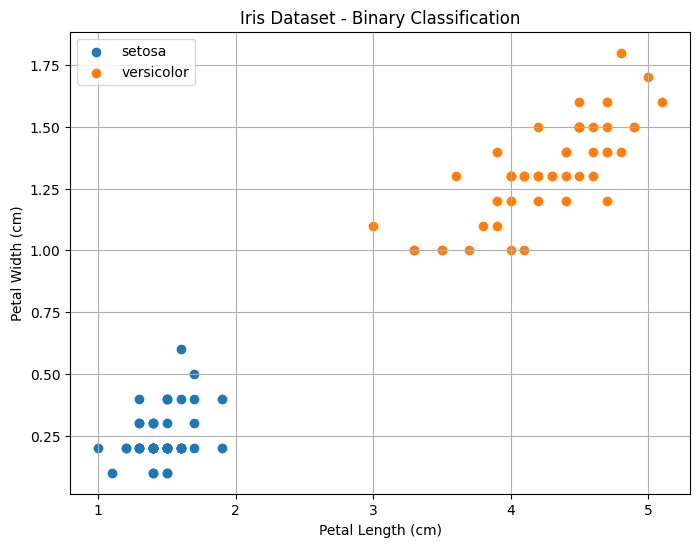


Training Samples: 80
Testing Samples: 20

Feature Scaling Completed!
SVM Model Created Successfully!
SVM Model Trained Successfully!

Predictions Generated Successfully!

First 10 Predictions:
[1 1 1 1 0 0 0 1 0 0]

First 10 Actual Values:
[1 1 1 1 0 0 0 1 0 0]

Accuracy: 1.0
Precision: 1.0
Recall : 1.0
F1 Score : 1.0

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      1.00      1.00        10

    accuracy                           1.00        20
   macro avg       1.00      1.00      1.00        20
weighted avg       1.00      1.00      1.00        20


Confusion Matrix:
[[10  0]
 [ 0 10]]


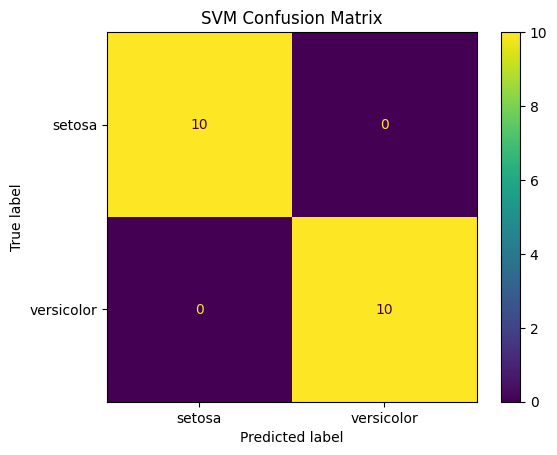


Linear SVM for Visualization Trained Successfully!


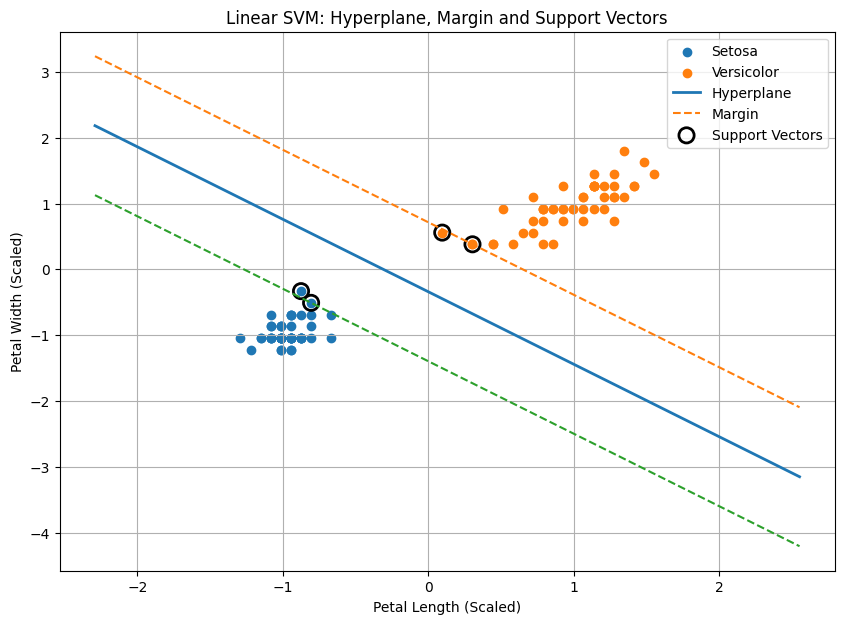

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, ConfusionMatrixDisplay
)

iris = load_iris()
print("Dataset Loaded Successfully!")

df = pd.DataFrame(iris.data, columns=iris.feature_names)
df["target"] = iris.target

print("\nFirst 5 Rows:")
print(df.head())

print("\nDataset Shape:")
print(df.shape)

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
print(df.describe())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nNumber of Duplicate Rows:")
print(df.duplicated().sum())

df = df.drop_duplicates().reset_index(drop=True)

print("Number of Duplicate Rows After Removal:")
print(df.duplicated().sum())

print("Dataset Shape After Removing Duplicates:")
print(df.shape)

df = df[df["target"].isin([0, 1])].reset_index(drop=True)

print("\nSelected Classes:")
print(iris.target_names[[0, 1]])

print("\nTarget Value Counts:")
print(df["target"].value_counts())

X = df.drop("target", axis=1)
y = df["target"]

print("\nFeatures:")
print(X.columns)

print("\nFeature Shape:")
print(X.shape)

print("\nTarget Shape:")
print(y.shape)

plt.figure(figsize=(8, 6))

for i, name in zip([0, 1], iris.target_names[[0, 1]]):
    plt.scatter(X.loc[y == i, X.columns[2]], X.loc[y == i, X.columns[3]], label=name)

plt.xlabel("Petal Length (cm)")
plt.ylabel("Petal Width (cm)")
plt.title("Iris Dataset - Binary Classification")
plt.legend()
plt.grid(True)
plt.show()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print("\nTraining Samples:", X_train.shape[0])
print("Testing Samples:", X_test.shape[0])

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("\nFeature Scaling Completed!")

svm_model = SVC(kernel="linear", C=1.0)
print("SVM Model Created Successfully!")

svm_model.fit(X_train_scaled, y_train)
print("SVM Model Trained Successfully!")

y_pred = svm_model.predict(X_test_scaled)

print("\nPredictions Generated Successfully!")
print("\nFirst 10 Predictions:")
print(y_pred[:10])

print("\nFirst 10 Actual Values:")
print(y_test.values[:10])

accuracy = accuracy_score(y_test, y_pred)
print("\nAccuracy:", accuracy)

precision = precision_score(y_test, y_pred, average="weighted")
recall = recall_score(y_test, y_pred, average="weighted")
f1 = f1_score(y_test, y_pred, average="weighted")

print("Precision:", precision)
print("Recall :", recall)
print("F1 Score :", f1)

print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=iris.target_names[[0, 1]]))

cm = confusion_matrix(y_test, y_pred)
print("\nConfusion Matrix:")
print(cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=iris.target_names[[0, 1]]
)
disp.plot()
plt.title("SVM Confusion Matrix")
plt.show()

X_2d = df.iloc[:, [2, 3]]
y_2d = df["target"]

scaler_2d = StandardScaler()
X_2d_scaled = scaler_2d.fit_transform(X_2d)

linear_svm = SVC(kernel="linear", C=1.0)
linear_svm.fit(X_2d_scaled, y_2d)

print("\nLinear SVM for Visualization Trained Successfully!")

w = linear_svm.coef_[0]
b = linear_svm.intercept_[0]

x_values = np.linspace(
    X_2d_scaled[:, 0].min() - 1,
    X_2d_scaled[:, 0].max() + 1,
    500
)

hyperplane = -(w[0] * x_values + b) / w[1]
margin_positive = -(w[0] * x_values + b - 1) / w[1]
margin_negative = -(w[0] * x_values + b + 1) / w[1]

plt.figure(figsize=(10, 7))

plt.scatter(
    X_2d_scaled[y_2d.values == 0, 0],
    X_2d_scaled[y_2d.values == 0, 1],
    label="Setosa"
)

plt.scatter(
    X_2d_scaled[y_2d.values == 1, 0],
    X_2d_scaled[y_2d.values == 1, 1],
    label="Versicolor"
)

plt.plot(x_values, hyperplane, linewidth=2, label="Hyperplane")
plt.plot(x_values, margin_positive, linestyle="--", label="Margin")
plt.plot(x_values, margin_negative, linestyle="--")

plt.scatter(
    linear_svm.support_vectors_[:, 0],
    linear_svm.support_vectors_[:, 1],
    s=120,
    facecolors="none",
    edgecolors="black",
    linewidths=2,
    label="Support Vectors"
)

plt.xlabel("Petal Length (Scaled)")
plt.ylabel("Petal Width (Scaled)")
plt.title("Linear SVM: Hyperplane, Margin and Support Vectors")
plt.legend()
plt.grid(True)
plt.show()